> **学生作业版说明**  
> 本 Notebook 为学生作业版，部分关键代码单元已被替换为待补全骨架。  
> 请结合 `README.md`、`assignment.md` 与 `starter.py` 完成实验。  
> 提交前请确认：代码可运行、指标齐全、报告完整。

In [1]:
import os, gzip, shutil, urllib.request
base = 'https://raw.githubusercontent.com/Heptazero/ml-course-labs/main/machine-learning/homework/'
if not os.path.exists('neural_network.py'):
    urllib.request.urlretrieve(base + 'neural_network.py', 'neural_network.py')
if not os.path.exists('fashion-mnist_train.csv'):
    if not os.path.exists('fashion-mnist_train.csv.gz'):
        urllib.request.urlretrieve(base + 'fashion-mnist_train.csv.gz', 'fashion-mnist_train.csv.gz')
    with gzip.open('fashion-mnist_train.csv.gz', 'rb') as f_in, open('fashion-mnist_train.csv', 'wb') as f_out:
        shutil.copyfileobj(f_in, f_out)

### 任务：时装类别识别
#### 【数据集介绍】
&ensp;&ensp;时装类别识别问题的任务是预测一张图片中的时装类别。时装类别识别问题的数据来自Zalando Research。在时装数据集中，共有60 000张时装的图片。每张图片表示一个28X28的像素灰度矩阵，并且含有一个属于{0, 1…,9}的标签，用于表明图片中所示的时装类别。时装总共有10种类别：T恤衫、长裤、套头衫、连衣裙、外套、高跟鞋、衬衣、休闲鞋、提包以及靴子，对应的类别号为0~9。图8.33是各类别的时装数据采样。
![image-3](./image-3.png)
#### 【任务目标】
&ensp;&ensp;用神经网络模型来求解时装类别识别问题
#### 【任务步骤】
1. 生成训练数据与测试数据
2. 数据标签采用向量标签形式
3. 生成模型的网络结构
4. 指定损失函数
5. 训练模型
6. 测试模型
7. 进行Softmax变换
8. 用最大概率分类函数对类别进行预测
9. 计算预测的准确率等

### 请在下载实验数据处下载时装数据fashion-mnist_train.csv至当前目录。

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neural_network as nn
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPClassifier

In [3]:
# 读取时装数据
def get_data():
    df = pd.read_csv("./fashion-mnist_train.csv")
    y = df['label'].values
    df = df.drop(['label'], axis=1)
    X = df.values
    return X, y

In [4]:
# 生成训练数据与测试数据
X, c = get_data()
encoder  = OneHotEncoder()
y = encoder.fit_transform(c.reshape(-1, 1)).toarray()
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, random_state = 0, test_size = 0.2)

In [5]:
#####  Start Code Here  #####
# 像素归一化到 [0, 1]
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 构建两层网络：784 -> 128 (ReLU) -> 10
np.random.seed(42)
layers = [
    nn.Layer(784, 128, nn.ReLUActivator()),
    nn.Layer(128, 10, nn.IdentityActivator())
]
loss = nn.SoftmaxCrossEntropy()
model = nn.NeuralNetwork(layers, loss)

# 训练模型
model.fit(X_train, y_train, N=288000, learning_rate=0.005)

# 测试与 Softmax 预测
y_pred = model.predict(X_test)
p_pred = nn.softmax(y_pred)
c_pred = np.argmax(p_pred, axis=1)
#####  End Code Here  #####

In [6]:
# 计算指标，本指标使用加权的方式计算多分类问题
accuracy = accuracy_score(c_test, c_pred)
precision = precision_score(c_test, c_pred, average='weighted')
recall = recall_score(c_test, c_pred, average='weighted')
f1 = f1_score(c_test, c_pred, average='weighted')
print("accuracy = {}".format(accuracy))
print("precision = {}".format(precision))
print("recall = {}".format(recall))
print("f1 = {}".format(f1))

# sklearn 对照验证
sk_mlp = MLPClassifier(hidden_layer_sizes=(128,), activation='relu', solver='sgd',
                       learning_rate_init=0.005, max_iter=20, random_state=42)
sk_mlp.fit(X_train, c_train)
sk_pred = sk_mlp.predict(X_test)
print("sklearn accuracy = {}".format(accuracy_score(c_test, sk_pred)))
print("sklearn precision = {}".format(precision_score(c_test, sk_pred, average='weighted')))
print("sklearn recall = {}".format(recall_score(c_test, sk_pred, average='weighted')))
print("sklearn f1 = {}".format(f1_score(c_test, sk_pred, average='weighted')))

accuracy = 0.8735
precision = 0.8745616152310017
recall = 0.8735
f1 = 0.8724019607587186


sklearn accuracy = 0.8700833333333333
sklearn precision = 0.8705206303089961
sklearn recall = 0.8700833333333333
sklearn f1 = 0.8684399804219451


/Users/heptazero/.gemini/antigravity/scratch/ml-lab9/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


N =  24000 | train acc = 0.8295 | test acc = 0.8253


N =  48000 | train acc = 0.8442 | test acc = 0.8347


N =  96000 | train acc = 0.8601 | test acc = 0.8519


N = 144000 | train acc = 0.8773 | test acc = 0.8689


N = 192000 | train acc = 0.8785 | test acc = 0.8641


N = 240000 | train acc = 0.8856 | test acc = 0.8663


N = 288000 | train acc = 0.8910 | test acc = 0.8735


N = 384000 | train acc = 0.9054 | test acc = 0.8857


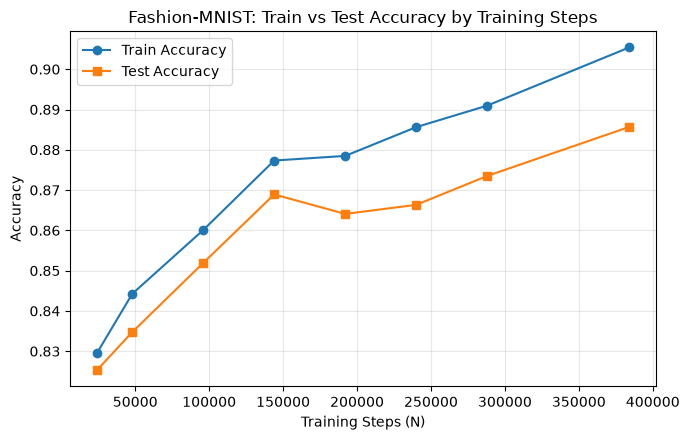

In [7]:
# 训练步数与过拟合分析
np.random.seed(42)
curve_model = nn.NeuralNetwork(
    [nn.Layer(784, 128, nn.ReLUActivator()), nn.Layer(128, 10, nn.IdentityActivator())],
    nn.SoftmaxCrossEntropy()
)
step_increments = [24000, 24000, 48000, 48000, 48000, 48000, 48000, 96000]
steps_list = []
train_acc_list = []
test_acc_list = []
total_steps = 0

for inc in step_increments:
    curve_model.fit(X_train, y_train, N=inc, learning_rate=0.005)
    total_steps += inc
    tr_pred = np.argmax(nn.softmax(curve_model.predict(X_train)), axis=1)
    te_pred = np.argmax(nn.softmax(curve_model.predict(X_test)), axis=1)
    tr_acc = accuracy_score(c_train, tr_pred)
    te_acc = accuracy_score(c_test, te_pred)
    steps_list.append(total_steps)
    train_acc_list.append(tr_acc)
    test_acc_list.append(te_acc)
    print(f"N = {total_steps:6d} | train acc = {tr_acc:.4f} | test acc = {te_acc:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(steps_list, train_acc_list, marker='o', label='Train Accuracy')
plt.plot(steps_list, test_acc_list, marker='s', label='Test Accuracy')
plt.xlabel('Training Steps (N)')
plt.ylabel('Accuracy')
plt.title('Fashion-MNIST: Train vs Test Accuracy by Training Steps')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

lr = 0.001 | ReLU test acc = 0.8452 | Sigmoid test acc = 0.8042


lr = 0.005 | ReLU test acc = 0.8519 | Sigmoid test acc = 0.8414


lr = 0.01  | ReLU test acc = 0.8217 | Sigmoid test acc = 0.8502


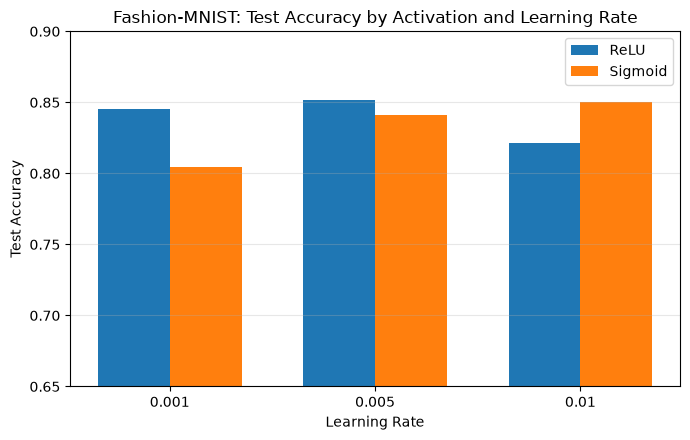

In [8]:
# 激活函数与学习率对比实验
lrs = [0.001, 0.005, 0.01]
relu_accs = []
sigmoid_accs = []

for lr in lrs:
    np.random.seed(42)
    m_relu = nn.NeuralNetwork(
        [nn.Layer(784, 128, nn.ReLUActivator()), nn.Layer(128, 10, nn.IdentityActivator())],
        nn.SoftmaxCrossEntropy()
    )
    m_relu.fit(X_train, y_train, N=96000, learning_rate=lr)
    acc_r = accuracy_score(c_test, np.argmax(nn.softmax(m_relu.predict(X_test)), axis=1))
    relu_accs.append(acc_r)

    np.random.seed(42)
    m_sig = nn.NeuralNetwork(
        [nn.Layer(784, 128, nn.SigmoidActivator()), nn.Layer(128, 10, nn.IdentityActivator())],
        nn.SoftmaxCrossEntropy()
    )
    m_sig.fit(X_train, y_train, N=96000, learning_rate=lr)
    acc_s = accuracy_score(c_test, np.argmax(nn.softmax(m_sig.predict(X_test)), axis=1))
    sigmoid_accs.append(acc_s)
    print(f"lr = {lr:<5} | ReLU test acc = {acc_r:.4f} | Sigmoid test acc = {acc_s:.4f}")

x = np.arange(len(lrs))
w = 0.35
plt.figure(figsize=(7, 4.5))
plt.bar(x - w / 2, relu_accs, width=w, label='ReLU')
plt.bar(x + w / 2, sigmoid_accs, width=w, label='Sigmoid')
plt.xticks(x, [str(lr) for lr in lrs])
plt.xlabel('Learning Rate')
plt.ylabel('Test Accuracy')
plt.title('Fashion-MNIST: Test Accuracy by Activation and Learning Rate')
plt.ylim(0.65, 0.90)
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()